# Proyecto 3 · Sentiment Analysis RELOADED
## Postura frente al aborto en comentarios de YouTube: *pro-vida* vs. *pro-aborto*

**Tema controversial:** aborto. Cada comentario (en español) se clasifica según la postura que expresa:

| Etiqueta | Significado |
|---|---|
| `vida` | Postura **pro-vida** (en contra del aborto) |
| `aborto` | Postura **pro-aborto** (a favor de la legalización / de la decisión de abortar) |
| `ninguno` | Sin postura identificable sobre el aborto (agradecimientos, mensajes de apoyo, ataques genéricos, comentarios fuera de tema…) |

**Contenido**

0. Configuración y carga de datos
1. Parte 1 · Preprocesamiento y línea base (BoW / TF-IDF + regresión logística)
2. Parte 2 · Ingeniería de características con POS y NER (spaCy) + BiLSTM
3. Parte 3 · Transformers (fine-tuning de BETO y RoBERTuito)
4. Parte 4 · Modelos híbridos (n-gramas de POS, n-gramas con entidades, embeddings mixtos + atención)
5. Parte 5 · Evaluación, comparación y análisis de errores
6. Reporte resumen

## 0. Configuración y carga de datos

In [1]:
import os, re, gc, math, random, time, warnings
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

import spacy
from langdetect import detect_langs, DetectorFactory

from sklearn.model_selection import StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             f1_score, confusion_matrix)
from scipy.sparse import hstack

import transformers
from transformers import (AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup)
transformers.logging.set_verbosity_error()

SEED = 42
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

set_seed(SEED)
DetectorFactory.seed = 0

LABELS = ["aborto", "vida", "ninguno"]           # orden fijo de las clases
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
COLORS = {"aborto": "#2A9D8F", "vida": "#E9A03B", "ninguno": "#8D99AE"}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
if DEVICE == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.6)   # deja margen a otros procesos de la GPU

print("torch", torch.__version__, "| transformers", transformers.__version__, "| spaCy", spacy.__version__, "| dispositivo:", DEVICE)

torch 2.15.0 | transformers 5.22.2 | spaCy 3.8.18 | dispositivo: mps


### 0.1 Recolección y etiquetado

**Fuente.** Comentarios públicos de YouTube descargados con la YouTube Data API v3 (`SentimentAnalysisTransformers/stance/collect.py`). Se hicieron 8 búsquedas en español con región México, 4 orientadas a cada postura (por ejemplo, *"marea verde aborto legal México"* y *"marcha por la vida aborto México"*), que devolvieron 117 videos. Cada video se clasificó por título y canal: 24 de contenido proelección, 28 provida, 57 mixtos (noticieros y debates) y 8 descartados por no tratar el tema. De cada video se bajaron hasta 500 comentarios principales, ordenados por relevancia: **6,665 comentarios de 96 videos** (4 tenían los comentarios desactivados). No se guardaron nombres de autores.

**Primer intento: etiquetar por fuente.** La idea inicial era asignar a cada comentario la postura del video donde aparece, reforzada con frases semilla explícitas (*"mi cuerpo, mi decisión"*, *"no al aborto"*, *"estoy a favor del aborto"*). Antes de usarlo se validó contra una muestra etiquetada a mano:

| Origen de la etiqueta | Acierto contra la etiqueta manual | Comentarios |
|---|---|---|
| Postura del video | 31 % | 36 |
| Frase semilla | 87 % | 15 |

La postura del video acierta menos que el azar: los videos proelección reciben sobre todo comentarios provida, que llegan a debatir. Además, el 37 % de los comentarios no expresa ninguna postura. Por eso se descartó el etiquetado por fuente y se etiquetó cada comentario por su contenido, en tres clases (`vida`, `aborto`, `ninguno`).

**Etiquetado.** 176 comentarios se etiquetaron a mano. Los otros 824 los etiquetó un modelo de lenguaje (Claude Haiku 5.5) con las mismas definiciones de clase, y se validó mezclando a ciegas los 176 manuales entre los que tenía que etiquetar:

| Medida contra las etiquetas manuales (n = 176) | Valor |
|---|---|
| Acuerdo | 77 % |
| Kappa de Cohen | 0.62 |
| Postura invertida (`vida` ↔ `aborto`) entre los 116 con postura | 6 % |

Casi todo el desacuerdo es entre `vida` y `ninguno`. Las etiquetas del modelo tienen, por lo tanto, un ruido cercano al 23 %, que pone un techo a las métricas de todos los clasificadores.

**Muestra.** 1,000 comentarios en español (verificado con `langdetect`), de al menos 5 palabras y sin duplicados: 200 de una primera muestra y 800 adicionales de hasta 150 palabras, con un máximo de 60 por video para que ningún video domine. Como los comentarios proelección son escasos (12 % de la primera muestra), entre los 800 se incluyeron todos los que contenían una frase semilla proelección (59); esto sesga ligeramente esa clase hacia posturas explícitas.


### 0.2 Carga del dataset
Los comentarios se encuentran en un único archivo (`comentarios_aborto.csv`) con tres columnas:
`comment_id`, `text` y `postura` (la etiqueta asignada manualmente).

In [2]:
raw = pd.read_csv("comentarios_aborto.csv")
print("Comentarios únicos en el corpus:", len(raw))
print("Con etiqueta de postura       :", raw.postura.notna().sum())
print("Sin etiqueta                  :", raw.postura.isna().sum())
raw.head(3)

Comentarios únicos en el corpus: 200
Con etiqueta de postura       : 81
Sin etiqueta                  : 119


,comment_id,text,postura
0,UgwSlHXhst0JQCHos7p4AaABAg,"Cuanta ignorancia por Dios. Buenos argumentos,...",vida
1,Ugzy20w2_JKQ9COrYpt4AaABAg,"El ser católica o no católica, no tiene nada q...",vida
2,UgxkZpaVIJrHHVyCefp4AaABAg,aberrante mezclar a Dios en esto\nlean un poco...,ninguno


### 0.3 Preprocesamiento básico y verificación del idioma
Se limpia el texto de URLs, menciones y espacios repetidos. **No** se pasa a minúsculas ni se quitan emojis/puntuación en esta etapa:
los transformers los aprovechan y cada modelo clásico aplica su propia normalización. Después se verifica el idioma con `langdetect`,
porque BETO, RoBERTuito y los vectores de spaCy son **modelos en español**: un comentario en otro idioma degradaría sus predicciones.

In [3]:
URL_RE = re.compile(r"https?://\S+|www\.\S+")

def clean_text(t):
    t = URL_RE.sub(" ", str(t))
    t = re.sub(r"@\w+", " ", t)          # menciones
    t = re.sub(r"\s+", " ", t)           # saltos de línea / espacios repetidos
    return t.strip()

raw["text_clean"] = raw.text.map(clean_text)
assert (raw.text_clean.str.len() > 0).all(), "hay comentarios vacíos tras la limpieza"
print("Textos duplicados:", raw.text_clean.duplicated().sum())

def detect_lang(t):
    try:
        best = detect_langs(t)[0]
        return best.lang, best.prob
    except Exception:
        return "??", 0.0

lang = raw.text_clean.map(detect_lang)
raw["lang"] = [l for l, _ in lang]
print("\nIdioma detectado:")
print(raw.lang.value_counts().to_string())

Textos duplicados: 0

Idioma detectado:
lang
es    200


Todos los comentarios son detectados como español, por lo que **no hace falta traducir ni filtrar**: se usan modelos preentrenados en español
(BETO, RoBERTuito y `es_core_news_md`) de forma consistente con el idioma del corpus.

### 0.4 Exploración de los datos
El aprendizaje supervisado (y toda la evaluación) usa únicamente los comentarios con etiqueta.

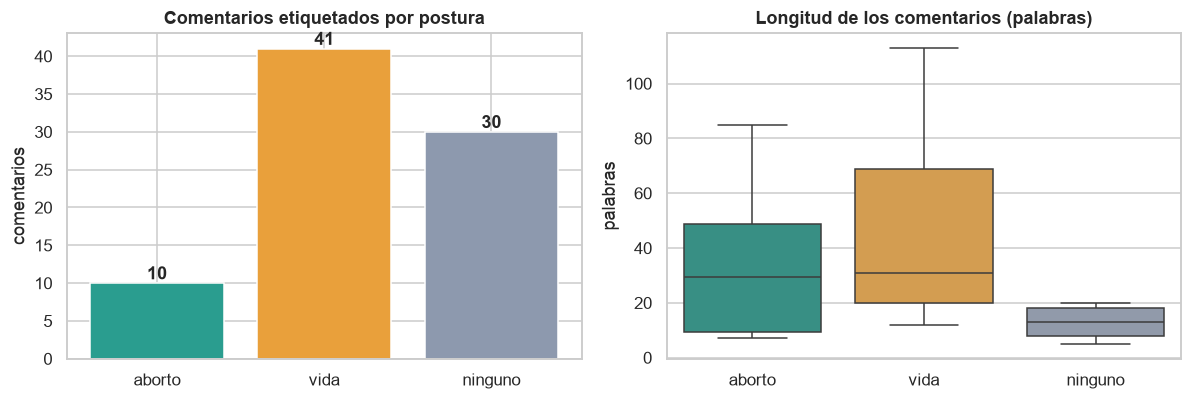

Comentarios etiquetados: 81
         count  mean   std   min   25%   50%   75%    max
postura                                                  
aborto    10.0  59.8  97.0   7.0   9.5  29.5  48.8  327.0
vida      41.0  53.9  49.9  12.0  20.0  31.0  69.0  230.0
ninguno   30.0  15.3  11.2   5.0   8.0  13.0  18.0   52.0


In [4]:
data = raw[raw.postura.notna()].reset_index(drop=True).copy()
data["y"] = data.postura.map(LABEL2ID)
data["n_palabras"] = data.text_clean.str.split().str.len()
y = data["y"].values

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
counts = data.postura.value_counts().reindex(LABELS)
axes[0].bar(counts.index, counts.values, color=[COLORS[l] for l in counts.index])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 0.5, str(v), ha="center", fontweight="bold")
axes[0].set_title("Comentarios etiquetados por postura"); axes[0].set_ylabel("comentarios")

sns.boxplot(data=data, x="postura", y="n_palabras", order=LABELS, palette=COLORS, ax=axes[1], showfliers=False)
axes[1].set_title("Longitud de los comentarios (palabras)"); axes[1].set_xlabel(""); axes[1].set_ylabel("palabras")
plt.tight_layout(); plt.show()

print("Comentarios etiquetados:", len(data))
print(data.groupby("postura").n_palabras.describe().round(1).reindex(LABELS))

In [5]:
pd.set_option("display.max_colwidth", 170)
ejemplos = pd.concat([g.sample(3, random_state=SEED) for _, g in data.groupby("postura")])[["postura", "text_clean"]]
ejemplos.assign(text_clean=ejemplos.text_clean.str.slice(0, 165)).reset_index(drop=True)

,postura,text_clean
0,aborto,"Yo estoy en contra, pero en lo unico que estoy de acuerdo, es que se realize en casos de violacion, en todo lo demas, ni hablar. Uno de los argumentos es, legalizarl"
1,aborto,Pro-vida: el aborto es machismo😡😡😡😡😡 Yo: ._.
2,aborto,"Yo estoy a favor del aborto siempre y cuando sea dentro de los primeros 3 meses de gestación, cuando apenas es un cigoto. Abortar fuera de ese tiempo es un acto horr"
3,ninguno,"Corrección, más de 6 mil personas 💙🇲🇽💙"
4,ninguno,"Estas personas que pecan luego se refugian en el nombre dios, unas blasfemias nunca van a ir al cielo"
5,ninguno,"Que le escuchen bien los de PPVOX, hazte oir y los del rosario y misa diaria...Almeidaaaa!!! oyes bien????"
6,vida,me ice un aborto tenía 15 años aborte porque me sentía sola débil pequeñita mi ex novio trato de determe pero yo estaba decidida ya que el era un chico problemático
7,vida,El aborto es matar a un bebe inocente digan lo que digan y lo justifiquen como lo justifiquen porque desde que es concebido el feto ya tiene vida y solo Dios se la p
8,vida,40 días por la vida oramos frente a ese abortorio hace muchísimo años Estos bebés se les debe hacer el Bautismo de deseo ojalá con un nombre bíblico ❤


**Alcance y limitaciones del corpus.** El corpus con etiqueta es pequeño (81 comentarios) y está desbalanceado
(`vida` ≈ 51 %, `ninguno` ≈ 37 %, `aborto` ≈ 12 %). Por eso:

* Se usa **validación cruzada estratificada de 5 pliegues** (mismos pliegues para todos los modelos) y se reportan predicciones *out-of-fold*
  sobre los 81 comentarios; así cada comentario se evalúa exactamente una vez con un modelo que no lo vio.
* La métrica principal es **F1 macro** (trata igual a las tres clases), no la exactitud, que un clasificador trivial que siempre predice `vida` ya sitúa en ≈ 0.51.
* Se reportan intervalos de confianza por *bootstrap*: con tan pocos datos, diferencias de unos pocos puntos entre modelos **no son estadísticamente concluyentes**.
* Las clases se ponderan inversamente a su frecuencia en todos los modelos para no ignorar a la clase `aborto`.

In [6]:
N_FOLDS = 5
FOLDS = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y))
for k, (tr, te) in enumerate(FOLDS):
    print(f"pliegue {k}: train={len(tr):>2}  test={len(te):>2}  clases en test={np.bincount(y[te], minlength=3)}")

RESULTS = {}      # nombre -> dict(familia, proba, pred, fold_f1)

def class_weights(yy):
    c = np.bincount(yy, minlength=3).astype(float)
    return len(yy) / (3.0 * np.maximum(c, 1))

def compute_metrics(yt, yp):
    p, r, f, _ = precision_recall_fscore_support(yt, yp, labels=[0, 1, 2], average="macro", zero_division=0)
    pc = precision_recall_fscore_support(yt, yp, labels=[0, 1, 2], average=None, zero_division=0)[2]
    return dict(acc=accuracy_score(yt, yp), prec=p, rec=r, f1=f, f1_aborto=pc[0], f1_vida=pc[1], f1_ninguno=pc[2])

def boot_ci(yt, yp, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        idx = rng.integers(0, len(yt), len(yt))
        vals.append(f1_score(yt[idx], yp[idx], average="macro", labels=[0, 1, 2], zero_division=0))
    return np.percentile(vals, [2.5, 97.5])

def evaluate(name, family, fit_predict):
    """fit_predict(train_idx, test_idx) -> matriz (n_test, 3) de probabilidades."""
    t0 = time.time()
    proba = np.zeros((len(y), 3)); fold_f1 = []
    for k, (tr, te) in enumerate(FOLDS):
        set_seed(SEED + k)
        P = fit_predict(tr, te)
        proba[te] = P
        fold_f1.append(f1_score(y[te], P.argmax(1), average="macro", labels=[0, 1, 2], zero_division=0))
    pred = proba.argmax(1)
    RESULTS[name] = dict(family=family, proba=proba, pred=pred, fold_f1=np.array(fold_f1))
    m = compute_metrics(y, pred)
    print(f"{name:<44} acc={m['acc']:.3f}  F1 macro={m['f1']:.3f}  (por pliegue {np.mean(fold_f1):.3f} ± {np.std(fold_f1):.3f})  [{time.time()-t0:.0f}s]")

def results_table(names=None):
    rows = []
    for n, r in RESULTS.items():
        if names is not None and n not in names:
            continue
        m = compute_metrics(y, r["pred"]); lo, hi = boot_ci(y, r["pred"])
        rows.append({"Modelo": n, "Familia": r["family"],
                     "Accuracy": m["acc"], "Precision (macro)": m["prec"], "Recall (macro)": m["rec"], "F1 (macro)": m["f1"],
                     "F1 por pliegue": f"{r['fold_f1'].mean():.3f} ± {r['fold_f1'].std():.3f}",
                     "IC 95 % F1 (bootstrap)": f"[{lo:.2f}, {hi:.2f}]",
                     "F1 aborto": m["f1_aborto"], "F1 vida": m["f1_vida"], "F1 ninguno": m["f1_ninguno"]})
    t = pd.DataFrame(rows).set_index("Modelo")
    num = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "F1 aborto", "F1 vida", "F1 ninguno"]
    return t.style.format({c: "{:.3f}" for c in num}).background_gradient(subset=["F1 (macro)"], cmap="YlGn", vmin=0.2, vmax=0.8)

pliegue 0: train=64  test=17  clases en test=[2 9 6]
pliegue 1: train=65  test=16  clases en test=[2 8 6]
pliegue 2: train=65  test=16  clases en test=[2 8 6]
pliegue 3: train=65  test=16  clases en test=[2 8 6]
pliegue 4: train=65  test=16  clases en test=[2 8 6]


## Parte 1 · Línea base: BoW / TF-IDF + regresión logística
Primero se fija una referencia mínima (clasificador que siempre predice la clase mayoritaria) y después dos representaciones
tradicionales: **bolsa de palabras** (conteos de unigramas) y **TF-IDF con unigramas + bigramas**. Ambas alimentan una regresión logística con
`class_weight="balanced"`. Los vectorizadores se ajustan **dentro de cada pliegue** (solo con el train) para no filtrar información del test.

In [7]:
X_text = data.text_clean.values

def sk_fit_predict(make_model, X):
    def fp(tr, te):
        m = make_model()
        m.fit(X[tr], y[tr])
        return m.predict_proba(X[te])
    return fp

evaluate("Mayoría (referencia)", "Línea base", sk_fit_predict(lambda: DummyClassifier(strategy="prior"), X_text))

evaluate("BoW (unigramas) + LR", "Línea base", sk_fit_predict(
    lambda: make_pipeline(CountVectorizer(lowercase=True),
                          LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000)), X_text))

evaluate("TF-IDF (1-2 gramas) + LR", "Línea base", sk_fit_predict(
    lambda: make_pipeline(TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True),
                          LogisticRegression(C=10.0, class_weight="balanced", max_iter=3000)), X_text))

Mayoría (referencia)                         acc=0.506  F1 macro=0.224  (por pliegue 0.224 ± 0.003)  [0s]
BoW (unigramas) + LR                         acc=0.642  F1 macro=0.510  (por pliegue 0.486 ± 0.037)  [0s]
TF-IDF (1-2 gramas) + LR                     acc=0.568  F1 macro=0.396  (por pliegue 0.372 ± 0.126)  [0s]


**¿Qué palabras pesan más?** Coeficientes del modelo TF-IDF + LR ajustado con todos los comentarios etiquetados (solo para interpretación, no para evaluar).

In [8]:
vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)
Xall = vec.fit_transform(X_text)
lr_all = LogisticRegression(C=10.0, class_weight="balanced", max_iter=3000).fit(Xall, y)
names = np.array(vec.get_feature_names_out())
top = {LABELS[c]: list(names[np.argsort(-lr_all.coef_[c])[:10]]) for c in range(3)}
pd.DataFrame(top)

,aborto,vida,ninguno
0,pro vida,que,gracias patricia
1,pro,las,unieran abortado
2,aborto,estos,unieran
3,vida el,es,les unieran
4,machismo,con,ellos les
5,es machismo,que es,todos
6,machismo yo,puede,ellos
7,vida,son,chile
8,este planeta,el,no hables
9,somos un,es un,hables


### Comentarios · Línea base
* **Referencia:** predecir siempre `vida` da exactitud 0.506 pero F1 macro de solo 0.224; cualquier modelo útil debe superar ese F1.
* **BoW + LR** obtiene F1 macro **0.510** (exactitud 0.642), la mejor cifra de toda la tarea. **TF-IDF 1-2 gramas** baja a 0.396: con ~65 comentarios de entrenamiento por pliegue los bigramas añaden dimensiones casi todas de frecuencia 1 y la regresión con `C=10` probablemente se sobreajusta a `vida`
  (alta precisión pero recall de `ninguno` de solo 20 % y de `aborto` de 10 %).
* **Lectura de los coeficientes:** para `aborto` destacan *pro vida*, *machismo*, *este planeta* (comentarios que citan al bando contrario o argumentos de sobrepoblación); para `vida`, palabras funcionales (*que*, *las*, *estos*), señal de comentarios largos y argumentativos;
  para `ninguno`, frases repetidas (*gracias patricia*, *les unieran*) que son artefactos de pocos comentarios casi idénticos. Es decir, con tan pocos datos el modelo aprende en buena parte **estilo y longitud** y no tanto el contenido de la postura.

## Parte 2 · Ingeniería de características con POS y NER
Se usa **spaCy** (`es_core_news_md`) para obtener, por cada token, su etiqueta gramatical universal (**POS**), su tipo de entidad nombrada (**NER**: `PER`, `LOC`, `ORG`, `MISC`, o `O` si no pertenece a una entidad)
y su vector de palabra de 300 dimensiones (vectores estáticos incluidos en el modelo).

In [9]:
nlp = spacy.load("es_core_news_md")
docs = list(nlp.pipe(data.text_clean.tolist(), batch_size=32))

UPOS = ["ADJ", "ADP", "ADV", "AUX", "CCONJ", "DET", "INTJ", "NOUN", "NUM", "PART", "PRON", "PROPN", "PUNCT", "SCONJ", "SYM", "VERB", "X"]
NERT = ["O", "PER", "LOC", "ORG", "MISC"]
POS2ID = {p: i for i, p in enumerate(UPOS)}
NER2ID = {n: i for i, n in enumerate(NERT)}

def replace_entities(toks, keep=()):
    """Sustituye cada entidad por ENT_<tipo> (salvo los tipos en `keep`)."""
    out = []
    for t in toks:
        if t.ent_type_ and t.ent_type_ not in keep:
            if t.ent_iob_ == "B":
                out.append("ENT_" + t.ent_type_)
        else:
            out.append(t.text)
    return " ".join(out)

def analyze(doc):
    toks = [t for t in doc if not t.is_space]
    return dict(
        words=[t.text for t in toks],
        pos=[t.pos_ if t.pos_ in POS2ID else "X" for t in toks],
        ner=[t.ent_type_ if t.ent_type_ in NER2ID else "O" for t in toks],
        vec=np.stack([t.vector for t in toks]).astype(np.float32),
        ents=[(e.text, e.label_) for e in doc.ents],
        text_ent=replace_entities(toks),
        text_ent_nomisc=replace_entities(toks, keep=("MISC",)),
    )

A = [analyze(d) for d in docs]
for a in A:
    a["pos_id"] = [POS2ID[p] for p in a["pos"]]
    a["ner_id"] = [NER2ID[n] for n in a["ner"]]

data["pos_str"] = [" ".join(a["pos"]) for a in A]
data["text_ent"] = [a["text_ent"] for a in A]
data["text_ent_nomisc"] = [a["text_ent_nomisc"] for a in A]
data["n_ents"] = [len(a["ents"]) for a in A]

i = data.index[data.n_ents > 0][0]
print("Original   :", data.text_clean[i][:150])
print("POS        :", " ".join(A[i]["pos"][:25]))
print("Entidades  :", A[i]["ents"])
print("Reemplazo  :", data.text_ent[i][:150])

Original   : Cuanta ignorancia por Dios. Buenos argumentos, los videos de Jonathan Ramos y Agustín laje que hablan en contra del aborto.
POS        : DET NOUN ADP PROPN PUNCT PROPN ADJ PUNCT DET NOUN ADP PROPN PROPN CCONJ PROPN PROPN PRON VERB ADP NOUN DET NOUN PUNCT
Entidades  : [('Dios', 'PER'), ('Buenos', 'LOC'), ('Jonathan Ramos', 'PER'), ('Agustín', 'PER')]
Reemplazo  : Cuanta ignorancia por ENT_PER . ENT_LOC argumentos , los videos de ENT_PER y ENT_PER laje que hablan en contra del aborto .


### 2.1 Distribución de POS y NER por postura

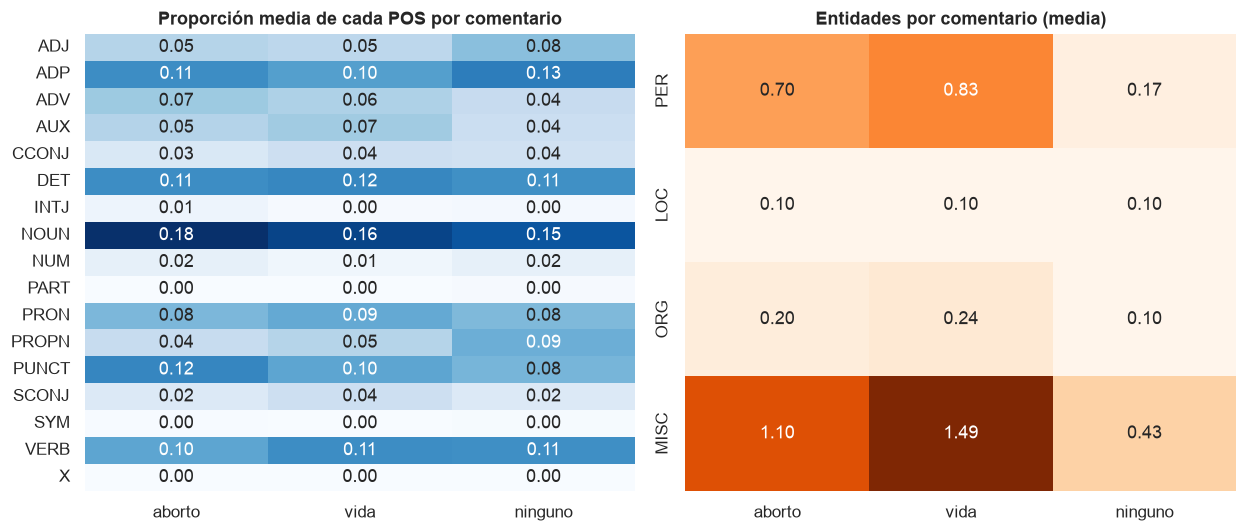

,aborto,vida,ninguno
0,LEGAL (ORG),Dios (MISC),Dios (MISC)
1,Amazon (PER),Dios (PER),Dios (PER)
2,Y ¿ (MISC),Jesús (PER),Palabra (ORG)
3,Ahora (MISC),No (MISC),Estúpidos (MISC)
4,Algunas de ellas (MISC),eh (ORG),Unico (MISC)


In [10]:
pos_rows = []
for a, c in zip(A, data.postura):
    n = len(a["pos"])
    cnt = np.bincount([POS2ID[p] for p in a["pos"]], minlength=len(UPOS)) / n
    pos_rows.append(dict(postura=c, **dict(zip(UPOS, cnt))))
pos_dist = pd.DataFrame(pos_rows).groupby("postura")[UPOS].mean().reindex(LABELS).T

ner_rows = []
for a, c in zip(A, data.postura):
    cnt = pd.Series([lab for _, lab in a["ents"]]).value_counts()
    ner_rows.append(dict(postura=c, **{k: cnt.get(k, 0) for k in NERT[1:]}))
ner_dist = pd.DataFrame(ner_rows).groupby("postura")[NERT[1:]].mean().reindex(LABELS).T

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5), gridspec_kw={"width_ratios": [1, 1]})
sns.heatmap(pos_dist, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set_title("Proporción media de cada POS por comentario"); axes[0].set_xlabel("")
sns.heatmap(ner_dist, annot=True, fmt=".2f", cmap="Oranges", cbar=False, ax=axes[1])
axes[1].set_title("Entidades por comentario (media)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

ent_tbl = {}
for c in LABELS:
    ents = [e for a, p in zip(A, data.postura) if p == c for e in a["ents"]]
    ent_tbl[c] = [f"{t} ({l})" for (t, l), _ in pd.Series(ents).value_counts().head(5).items()] if ents else []
pd.DataFrame({k: pd.Series(v) for k, v in ent_tbl.items()}).fillna("")

### 2.2 Estrategia 1 · Conteos de POS/NER por comentario
Vector de 22 dimensiones: proporción de cada POS (17), número de entidades de cada tipo (4) y log de la longitud. Se estandariza y se clasifica con regresión logística.

In [11]:
def tag_count_features(a):
    n = len(a["words"])
    pos = np.bincount(a["pos_id"], minlength=len(UPOS)) / n
    ent = np.bincount([NER2ID[l] for _, l in a["ents"]], minlength=len(NERT))[1:]
    return np.concatenate([pos, ent, [np.log1p(n)]])

X_cnt = np.stack([tag_count_features(a) for a in A])
evaluate("Conteos POS/NER + LR", "POS/NER", sk_fit_predict(
    lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, class_weight="balanced", max_iter=3000)), X_cnt))

Conteos POS/NER + LR                         acc=0.494  F1 macro=0.428  (por pliegue 0.413 ± 0.087)  [0s]


### 2.3 Estrategias 2 y 3 · BiLSTM con embeddings de etiquetas concatenados a los vectores de palabra
Cada token es la concatenación de su **vector de palabra** (300 d, congelado) con un **embedding entrenable de su POS** (16 d) y de su **etiqueta NER** (8 d).
La secuencia pasa por una **BiLSTM** (64 unidades por dirección), *max-pooling* sobre el tiempo, *dropout* y una capa lineal.
Se comparan tres variantes (solo palabras, palabras + POS, palabras + POS + NER). Con tan pocos datos cada pliegue promedia las probabilidades de 3 inicializaciones.

In [12]:
MAX_TOK = 100
EPOCHS_LSTM = 40
N_SEEDS = 3

class TagBiLSTM(nn.Module):
    def __init__(self, use_pos, use_ner, emb_dim=300, pos_dim=16, ner_dim=8, hid=64, drop=0.5):
        super().__init__()
        self.use_pos, self.use_ner = use_pos, use_ner
        self.pos_emb = nn.Embedding(len(UPOS), pos_dim) if use_pos else None
        self.ner_emb = nn.Embedding(len(NERT), ner_dim) if use_ner else None
        d = emb_dim + (pos_dim if use_pos else 0) + (ner_dim if use_ner else 0)
        self.lstm = nn.LSTM(d, hid, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(drop)
        self.out = nn.Linear(2 * hid, 3)

    def forward(self, vec, pos, ner, lengths):
        x = [vec]
        if self.use_pos: x.append(self.pos_emb(pos))
        if self.use_ner: x.append(self.ner_emb(ner))
        x = self.drop(torch.cat(x, -1))
        packed = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        h, _ = self.lstm(packed)
        h, _ = pad_packed_sequence(h, batch_first=True, total_length=vec.shape[1])
        mask = torch.arange(h.shape[1], device=h.device)[None, :] < lengths.to(h.device)[:, None]
        h = h.masked_fill(~mask.unsqueeze(-1), -1e9)
        return self.out(self.drop(h.max(1).values))

def seq_batch(ids):
    L = [min(len(A[i]["words"]), MAX_TOK) for i in ids]
    T = max(L)
    vec = torch.zeros(len(ids), T, 300); pos = torch.zeros(len(ids), T, dtype=torch.long); ner = torch.zeros_like(pos)
    for b, i in enumerate(ids):
        l = L[b]
        vec[b, :l] = torch.from_numpy(A[i]["vec"][:l])
        pos[b, :l] = torch.tensor(A[i]["pos_id"][:l]); ner[b, :l] = torch.tensor(A[i]["ner_id"][:l])
    return vec.to(DEVICE), pos.to(DEVICE), ner.to(DEVICE), torch.tensor(L)   # longitudes en CPU (pack_padded_sequence)

def bilstm_fit_predict(use_pos, use_ner):
    def fp(tr, te):
        P = np.zeros((len(te), 3))
        w = torch.tensor(class_weights(y[tr]), dtype=torch.float32, device=DEVICE)
        for s in range(N_SEEDS):
            set_seed(SEED + 100 * s)
            model = TagBiLSTM(use_pos, use_ner).to(DEVICE)
            opt = torch.optim.Adam(model.parameters(), lr=2e-3, weight_decay=1e-4)
            loss_fn = nn.CrossEntropyLoss(weight=w)
            for ep in range(EPOCHS_LSTM):
                model.train()
                perm = np.random.permutation(tr)
                for i in range(0, len(perm), 16):
                    b = perm[i:i + 16]
                    loss = loss_fn(model(*seq_batch(b)), torch.tensor(y[b], device=DEVICE))
                    opt.zero_grad(); loss.backward(); opt.step()
            model.eval()
            with torch.no_grad():
                P += torch.softmax(model(*seq_batch(te)), -1).cpu().numpy()
        return P / N_SEEDS
    return fp

evaluate("BiLSTM + vectores de palabra", "POS/NER", bilstm_fit_predict(False, False))
evaluate("BiLSTM + vectores + POS", "POS/NER", bilstm_fit_predict(True, False))
evaluate("BiLSTM + vectores + POS + NER", "POS/NER", bilstm_fit_predict(True, True))

BiLSTM + vectores de palabra                 acc=0.580  F1 macro=0.462  (por pliegue 0.429 ± 0.071)  [143s]
BiLSTM + vectores + POS                      acc=0.580  F1 macro=0.493  (por pliegue 0.472 ± 0.102)  [143s]
BiLSTM + vectores + POS + NER                acc=0.593  F1 macro=0.501  (por pliegue 0.464 ± 0.090)  [148s]


In [13]:
part2 = ["Mayoría (referencia)", "TF-IDF (1-2 gramas) + LR", "Conteos POS/NER + LR",
         "BiLSTM + vectores de palabra", "BiLSTM + vectores + POS", "BiLSTM + vectores + POS + NER"]
results_table(part2)

,Familia,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 por pliegue,IC 95 % F1 (bootstrap),F1 aborto,F1 vida,F1 ninguno
Modelo,,,,,,,,,,
Mayoría (referencia),Línea base,0.506,0.169,0.333,0.224,0.224 ± 0.003,"[0.19, 0.25]",0.000,0.672,0.000
TF-IDF (1-2 gramas) + LR,Línea base,0.568,0.764,0.417,0.396,0.372 ± 0.126,"[0.27, 0.52]",0.182,0.690,0.316
Conteos POS/NER + LR,POS/NER,0.494,0.451,0.423,0.428,0.413 ± 0.087,"[0.33, 0.53]",0.129,0.603,0.552
BiLSTM + vectores de palabra,POS/NER,0.580,0.470,0.473,0.462,0.429 ± 0.071,"[0.36, 0.57]",0.125,0.640,0.620
BiLSTM + vectores + POS,POS/NER,0.580,0.502,0.498,0.493,0.472 ± 0.102,"[0.38, 0.61]",0.235,0.605,0.638
BiLSTM + vectores + POS + NER,POS/NER,0.593,0.504,0.506,0.501,0.464 ± 0.090,"[0.38, 0.62]",0.222,0.623,0.657


### Comentarios · POS y NER
* **POS:** los comentarios `ninguno` tienen más adjetivos y preposiciones y menos auxiliares/subordinantes (son mensajes cortos de agradecimiento o exclamación); `aborto` tiene más sustantivos y puntuación. Son diferencias pequeñas pero consistentes con la longitud y el estilo de cada clase.
* **NER:** los comentarios `ninguno` casi no contienen entidades (0.17 `PER` por comentario frente a 0.70-0.83 en las otras clases), mientras que `vida` acumula muchas entidades `MISC` (1.49). Pero **el NER de spaCy es ruidoso en este dominio**: modelo entrenado con noticias, etiqueta *Dios* como `PER` o `MISC`,
  *Buenos* como `LOC` y *LEGAL* como `ORG`. Las "entidades" son, en gran medida, palabras con mayúscula, lo que limita su valor.
* **Modelos:** los conteos de POS/NER (22 números por comentario) alcanzan F1 0.428, por encima de la referencia, lo que confirma que la estructura gramatical aporta algo de señal. En la BiLSTM, añadir etiquetas mejora de forma monótona: solo vectores 0.462 → +POS 0.493 → +POS+NER **0.501**, y el F1 de `aborto` pasa de 0.13 a 0.22.
  La tendencia es la esperada, pero la variación entre pliegues (± 0.07-0.10) y los intervalos de confianza se traslapan: **no es una mejora demostrable** con 81 comentarios.

## Parte 3 · Modelos basados en Transformers (fine-tuning)
Se ajustan (*fine-tuning* completo, clasificación de 3 clases) dos modelos preentrenados **en español**:

* **BETO** (`dccuchile/bert-base-spanish-wwm-cased`): BERT entrenado con texto general en español.
* **RoBERTuito** (`pysentimiento/robertuito-base-uncased`): RoBERTa entrenado con tweets en español, es decir, lenguaje de redes sociales como el de estos comentarios (equivalente en español de BERTweet).

Configuración: AdamW (lr = 3e-5, *weight decay* 0.01), *warm-up* lineal del 10 %, lote de 8, 8 épocas, longitud máxima de 128 *subwords*,
pérdida de entropía cruzada ponderada por clase y modelo reinicializado desde el preentrenado en cada pliegue.

In [14]:
MAX_LEN = 128
EPOCHS_HF = 8
LR_ENC, LR_HEAD, BATCH = 3e-5, 1e-3, 8
BETO = "dccuchile/bert-base-spanish-wwm-cased"
ROBERTUITO = "pysentimiento/robertuito-base-uncased"

def collate(items, pad_id):
    B, T = len(items), max(len(it["input_ids"]) for it in items)
    ids = torch.full((B, T), pad_id, dtype=torch.long)
    att = torch.zeros(B, T, dtype=torch.long)
    pos = torch.zeros(B, T, dtype=torch.long); ner = torch.zeros(B, T, dtype=torch.long)
    for b, it in enumerate(items):
        n = len(it["input_ids"])
        ids[b, :n] = torch.tensor(it["input_ids"]); att[b, :n] = 1
        if "pos_ids" in it:
            pos[b, :n] = torch.tensor(it["pos_ids"]); ner[b, :n] = torch.tensor(it["ner_ids"])
    return {"input_ids": ids.to(DEVICE), "attention_mask": att.to(DEVICE), "pos_ids": pos.to(DEVICE), "ner_ids": ner.to(DEVICE)}

def encode_plain(tok):
    return [{"input_ids": tok(t, truncation=True, max_length=MAX_LEN)["input_ids"]} for t in data.text_clean]

class HFClassifier(nn.Module):
    """Fine-tuning estándar: encoder + cabeza de clasificación."""
    def __init__(self, name):
        super().__init__()
        self.hf = AutoModelForSequenceClassification.from_pretrained(name, num_labels=3)
    def forward(self, batch):
        out = self.hf(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"])
        return out.logits, None
    def param_groups(self, lr, head_lr):
        return [{"params": self.hf.parameters(), "lr": lr}]

def transformer_fit_predict(make_model, enc, pad_id, att_store=None):
    def fp(tr, te):
        model = make_model().to(DEVICE)
        opt = torch.optim.AdamW(model.param_groups(LR_ENC, LR_HEAD), weight_decay=0.01)
        steps = EPOCHS_HF * math.ceil(len(tr) / BATCH)
        sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
        loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(class_weights(y[tr]), dtype=torch.float32, device=DEVICE))
        for ep in range(EPOCHS_HF):
            model.train()
            perm = np.random.permutation(tr)
            for i in range(0, len(perm), BATCH):
                b = perm[i:i + BATCH]
                logits, _ = model(collate([enc[j] for j in b], pad_id))
                loss = loss_fn(logits, torch.tensor(y[b], device=DEVICE))
                opt.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step(); sched.step()
        model.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(te), 16):
                b = te[i:i + 16]
                logits, extra = model(collate([enc[j] for j in b], pad_id))
                out.append(torch.softmax(logits, -1).cpu().numpy())
                if extra is not None and att_store is not None:
                    for r, j in enumerate(b):
                        n = len(enc[j]["input_ids"])
                        att_store[j] = dict(word_ids=enc[j]["word_ids"], alpha=extra["att"][r, :n].cpu().numpy(),
                                            gate=None if extra["gate"] is None else float(extra["gate"][r, :n].mean()))
        del model, opt
        gc.collect()
        if DEVICE == "mps": torch.mps.empty_cache()
        return np.concatenate(out)
    return fp

tok_beto = AutoTokenizer.from_pretrained(BETO)
tok_rob = AutoTokenizer.from_pretrained(ROBERTUITO)
enc_beto, enc_rob = encode_plain(tok_beto), encode_plain(tok_rob)
n_trunc = sum(len(tok_beto(t)["input_ids"]) > MAX_LEN for t in data.text_clean)
print(f"Comentarios truncados a {MAX_LEN} subwords (BETO): {n_trunc} de {len(data)}")

evaluate("BETO (fine-tuning)", "Transformer",
         transformer_fit_predict(lambda: HFClassifier(BETO), enc_beto, tok_beto.pad_token_id))
evaluate("RoBERTuito (fine-tuning)", "Transformer",
         transformer_fit_predict(lambda: HFClassifier(ROBERTUITO), enc_rob, tok_rob.pad_token_id))

Comentarios truncados a 128 subwords (BETO): 6 de 81


W1108 21:50:37.596000 18885 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


BETO (fine-tuning)                           acc=0.617  F1 macro=0.434  (por pliegue 0.427 ± 0.077)  [88s]
RoBERTuito (fine-tuning)                     acc=0.593  F1 macro=0.427  (por pliegue 0.423 ± 0.070)  [87s]


In [15]:
results_table(["Mayoría (referencia)", "TF-IDF (1-2 gramas) + LR", "BiLSTM + vectores + POS + NER",
               "BETO (fine-tuning)", "RoBERTuito (fine-tuning)"])

,Familia,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 por pliegue,IC 95 % F1 (bootstrap),F1 aborto,F1 vida,F1 ninguno
Modelo,,,,,,,,,,
Mayoría (referencia),Línea base,0.506,0.169,0.333,0.224,0.224 ± 0.003,"[0.19, 0.25]",0.000,0.672,0.000
TF-IDF (1-2 gramas) + LR,Línea base,0.568,0.764,0.417,0.396,0.372 ± 0.126,"[0.27, 0.52]",0.182,0.690,0.316
BiLSTM + vectores + POS + NER,POS/NER,0.593,0.504,0.506,0.501,0.464 ± 0.090,"[0.38, 0.62]",0.222,0.623,0.657
BETO (fine-tuning),Transformer,0.617,0.413,0.460,0.434,0.427 ± 0.077,"[0.36, 0.50]",0.000,0.703,0.600
RoBERTuito (fine-tuning),Transformer,0.593,0.413,0.444,0.427,0.423 ± 0.070,"[0.35, 0.50]",0.000,0.682,0.600


### Comentarios · Transformers
* BETO (F1 macro 0.434, exactitud 0.617) y RoBERTuito (0.427, 0.593) quedan **por debajo de BoW y de la BiLSTM con etiquetas en F1 macro**, aunque superan la exactitud de la mayoría de los modelos clásicos. La causa es clara en las matrices de confusión: **ninguno de los dos acierta un solo comentario `aborto`** (F1 = 0). Con ~65 ejemplos de entrenamiento (8 de `aborto`) el *fine-tuning* converge a separar `vida` de `ninguno`
  y a ignorar la clase minoritaria, a pesar de la pérdida ponderada. En `vida` (F1 ≈ 0.70) y `ninguno` (0.60) rinden bien.
* El preentrenamiento en lenguaje de redes sociales (RoBERTuito) **no ofrece ventaja** frente a BETO en este corpus; la diferencia entre ambos es ruido.
* Conclusión: el conocimiento lingüístico previo no basta cuando la clase a detectar tiene 10 ejemplos y, además, depende de contexto implícito. Con más datos etiquetados (cientos de ejemplos por clase) es donde se esperaría que los transformers se despegaran.

## Parte 4 · Modelos híbridos
Se implementan las **tres** variantes propuestas en el enunciado.

### 4.1 N-gramas sintácticos (POS-tagged n-grams)
En lugar de palabras se usan **secuencias de etiquetas POS** (p. ej. `PRON VERB SCONJ`) y se extraen 1-, 2- y 3-gramas de etiquetas. Capturan patrones sintácticos (estilo del comentario) y reducen la dispersión. También se combinan con los n-gramas de palabras.

In [16]:
def lr_tfidf(ngram, lowercase, token_pattern=r"(?u)\b\w\w+\b", C=10.0):
    return make_pipeline(TfidfVectorizer(lowercase=lowercase, ngram_range=ngram, sublinear_tf=True, token_pattern=token_pattern),
                         LogisticRegression(C=C, class_weight="balanced", max_iter=3000))

evaluate("POS 1-3 gramas + LR", "Híbrido", sk_fit_predict(lambda: lr_tfidf((1, 3), False, r"\S+"), data.pos_str.values))

class WordPlusPOS:
    """TF-IDF de palabras (1-2) y de POS (1-3) concatenados + LR."""
    def __init__(self, word_col="text_clean", C=10.0):
        self.word_col, self.C = word_col, C
        self.vw = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), sublinear_tf=True)
        self.vp = TfidfVectorizer(lowercase=False, ngram_range=(1, 3), sublinear_tf=True, token_pattern=r"\S+")
        self.lr = LogisticRegression(C=C, class_weight="balanced", max_iter=3000)
    def _x(self, idx, fit):
        w, p = data[self.word_col].values[idx], data.pos_str.values[idx]
        if fit: return hstack([self.vw.fit_transform(w), self.vp.fit_transform(p)]).tocsr()
        return hstack([self.vw.transform(w), self.vp.transform(p)]).tocsr()
    def fit(self, idx, yy): self.lr.fit(self._x(idx, True), yy); return self
    def predict_proba(self, idx): return self.lr.predict_proba(self._x(idx, False))

def combo_fit_predict(word_col):
    def fp(tr, te):
        m = WordPlusPOS(word_col).fit(tr, y[tr])
        return m.predict_proba(te)
    return fp

evaluate("Palabras 1-2g + POS 1-3g + LR", "Híbrido", combo_fit_predict("text_clean"))

POS 1-3 gramas + LR                          acc=0.519  F1 macro=0.348  (por pliegue 0.345 ± 0.055)  [0s]
Palabras 1-2g + POS 1-3g + LR                acc=0.556  F1 macro=0.370  (por pliegue 0.366 ± 0.075)  [0s]


### 4.2 N-gramas con entidades sustituidas (NER-tag-enhanced n-grams)
Cada entidad se reemplaza por su tipo (`Patricia` → `ENT_PER`, `México` → `ENT_LOC`) antes de extraer los n-gramas, para generalizar sobre nombres propios.
Se prueban dos versiones: sustituyendo **todos** los tipos y sustituyendo solo `PER`/`LOC`/`ORG` (conservando `MISC`, donde spaCy suele colocar términos como *Dios*).

In [17]:
evaluate("N-gramas con entidades (ENT_*) + LR", "Híbrido", sk_fit_predict(lambda: lr_tfidf((1, 2), True), data.text_ent.values))
evaluate("N-gramas con entidades, sin MISC + LR", "Híbrido", sk_fit_predict(lambda: lr_tfidf((1, 2), True), data.text_ent_nomisc.values))
evaluate("Entidades (sin MISC) + POS 1-3g + LR", "Híbrido", combo_fit_predict("text_ent_nomisc"))

ex = data.index[data.n_ents >= 2][:3]
for i in ex:
    print("ORIG:", data.text_clean[i][:140]); print("ENT :", data.text_ent[i][:140]); print()

N-gramas con entidades (ENT_*) + LR          acc=0.556  F1 macro=0.389  (por pliegue 0.369 ± 0.136)  [0s]
N-gramas con entidades, sin MISC + LR        acc=0.556  F1 macro=0.379  (por pliegue 0.357 ± 0.130)  [0s]
Entidades (sin MISC) + POS 1-3g + LR         acc=0.519  F1 macro=0.340  (por pliegue 0.331 ± 0.101)  [0s]
ORIG: Cuanta ignorancia por Dios. Buenos argumentos, los videos de Jonathan Ramos y Agustín laje que hablan en contra del aborto.
ENT : Cuanta ignorancia por ENT_PER . ENT_LOC argumentos , los videos de ENT_PER y ENT_PER laje que hablan en contra del aborto .

ORIG: El ser católica o no católica, no tiene nada que ver con el aborto, lo que veo es que están victimando a la mujer y que debemos sentir pena 
ENT : El ser católica o no católica , no tiene nada que ver con el aborto , lo que veo es que están victimando a la mujer y que debemos sentir pen

ORIG: aberrante mezclar a Dios en esto lean un poco de la Palabra primero, por favor
ENT : aberrante mezclar a ENT_MISC en est

### 4.3 Embeddings mixtos + atención (BETO + etiquetas POS/NER)
Arquitectura de dos flujos que se entrena de extremo a extremo:

1. **Flujo contextual:** BETO produce un vector contextual de 768 d por *subword*.
2. **Flujo estructural:** los POS y NER de cada palabra (alineados a sus *subwords*) pasan por embeddings entrenables (32 d y 16 d) y una **BiGRU**; el resultado se proyecta a 768 d.
3. **Compuerta (*gating*):** `g = σ(W·[h; s])`, `f = g ⊙ h + (1 − g) ⊙ s`; el modelo decide por dimensión cuánto confiar en el flujo contextual y cuánto en el estructural.
4. **Atención aditiva:** `α = softmax(vᵀ tanh(W f))` pondera los tokens; el vector ponderado alimenta el clasificador.

Como control, se entrena también la misma arquitectura **sin** el flujo estructural (solo BETO + *pooling* por atención), para saber si una mejora viene de las etiquetas o del *pooling*.

In [18]:
class HybridTagAttention(nn.Module):
    def __init__(self, name, use_tags=True, tag_pos=32, tag_ner=16, gru=64, drop=0.3):
        super().__init__()
        self.use_tags = use_tags
        self.enc = AutoModel.from_pretrained(name)
        H = self.enc.config.hidden_size
        if use_tags:
            self.pos_emb = nn.Embedding(len(UPOS) + 1, tag_pos, padding_idx=0)     # 0 = [CLS]/[SEP]/relleno
            self.ner_emb = nn.Embedding(len(NERT) + 1, tag_ner, padding_idx=0)
            self.tag_rnn = nn.GRU(tag_pos + tag_ner, gru, batch_first=True, bidirectional=True)
            self.tag_proj = nn.Linear(2 * gru, H)
            self.gate = nn.Linear(2 * H, H)
        self.att = nn.Sequential(nn.Linear(H, 128), nn.Tanh(), nn.Linear(128, 1))
        self.drop = nn.Dropout(drop)
        self.cls = nn.Linear(H, 3)

    def forward(self, batch):
        mask = batch["attention_mask"]
        h = self.enc(input_ids=batch["input_ids"], attention_mask=mask).last_hidden_state
        g = None
        if self.use_tags:
            s, _ = self.tag_rnn(torch.cat([self.pos_emb(batch["pos_ids"]), self.ner_emb(batch["ner_ids"])], -1))
            s = self.tag_proj(s)
            g = torch.sigmoid(self.gate(torch.cat([h, s], -1)))
            f = g * h + (1 - g) * s
        else:
            f = h
        a = torch.softmax(self.att(f).squeeze(-1).masked_fill(mask == 0, -1e9), -1)
        pooled = (a.unsqueeze(-1) * f).sum(1)
        return self.cls(self.drop(pooled)), {"att": a, "gate": None if g is None else g.mean(-1)}

    def param_groups(self, lr, head_lr):
        enc_params = list(self.enc.parameters()); ids = {id(p) for p in enc_params}
        head = [p for p in self.parameters() if id(p) not in ids]
        return [{"params": enc_params, "lr": lr}, {"params": head, "lr": head_lr}]

def encode_tagged(tok):
    """Tokeniza las palabras de spaCy y alinea POS/NER a cada subword."""
    out = []
    for a in A:
        e = tok(a["words"], is_split_into_words=True, truncation=True, max_length=MAX_LEN)
        wid = e.word_ids()
        out.append(dict(input_ids=e["input_ids"], word_ids=wid,
                        pos_ids=[0 if w is None else a["pos_id"][w] + 1 for w in wid],
                        ner_ids=[0 if w is None else a["ner_id"][w] + 1 for w in wid]))
    return out

enc_tag = encode_tagged(tok_beto)
ATT = {}      # índice del comentario -> atención por subword (modelo con etiquetas)

evaluate("BETO + atención (sin etiquetas)", "Híbrido",
         transformer_fit_predict(lambda: HybridTagAttention(BETO, use_tags=False), enc_tag, tok_beto.pad_token_id))
evaluate("BETO + POS/NER (gating + atención)", "Híbrido",
         transformer_fit_predict(lambda: HybridTagAttention(BETO, use_tags=True), enc_tag, tok_beto.pad_token_id, att_store=ATT))

BETO + atención (sin etiquetas)              acc=0.605  F1 macro=0.432  (por pliegue 0.429 ± 0.105)  [93s]
BETO + POS/NER (gating + atención)           acc=0.642  F1 macro=0.463  (por pliegue 0.461 ± 0.064)  [111s]


Valor medio de la compuerta (1 = solo flujo contextual de BETO, 0 = solo etiquetas): 0.608


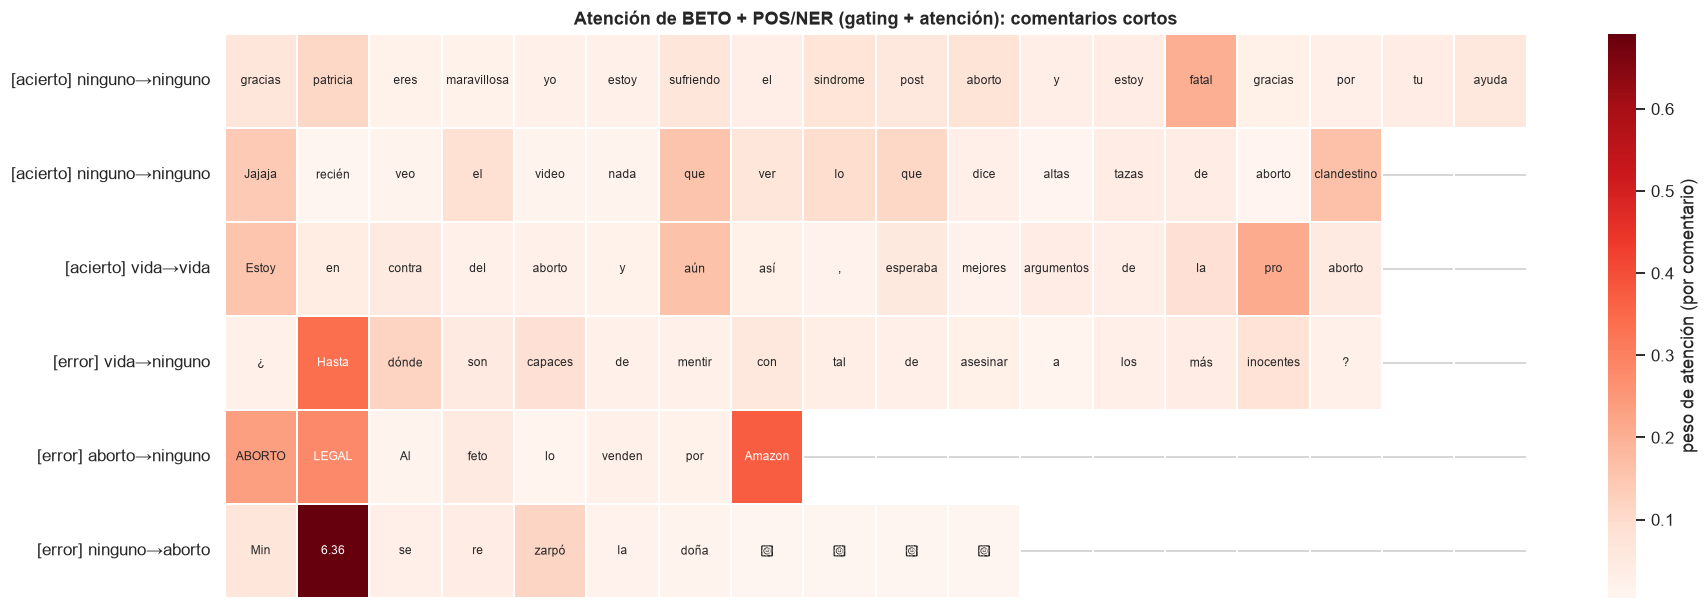

In [19]:
print(f"Valor medio de la compuerta (1 = solo flujo contextual de BETO, 0 = solo etiquetas): "
      f"{np.mean([v['gate'] for v in ATT.values()]):.3f}")

def word_attention(j):
    """Agrega la atención de subwords a nivel de palabra (sin tokens especiales) y la renormaliza."""
    st = ATT[j]; words = A[j]["words"]; w = np.zeros(len(words))
    for k, wi in enumerate(st["word_ids"]):
        if wi is not None: w[wi] += st["alpha"][k]
    return words, w / max(w.sum(), 1e-9)

def attention_figure(model_name, n_each=3, max_words=18, seed=SEED):
    pred = RESULTS[model_name]["pred"]; rng = np.random.default_rng(seed)
    cand = [j for j in ATT if 6 <= len(A[j]["words"]) <= max_words]
    ok = [j for j in cand if pred[j] == y[j]]; bad = [j for j in cand if pred[j] != y[j]]
    chosen = list(rng.permutation(ok)[:n_each]) + list(rng.permutation(bad)[:n_each])
    M = np.full((len(chosen), max_words), np.nan); S = np.full((len(chosen), max_words), "", dtype=object); rows = []
    for r, j in enumerate(chosen):
        words, w = word_attention(j)
        M[r, :len(words)] = w; S[r, :len(words)] = words
        rows.append(("[acierto] " if pred[j] == y[j] else "[error] ") + f"{LABELS[y[j]]}→{LABELS[pred[j]]}")
    fig, ax = plt.subplots(figsize=(max_words * 0.95, 0.75 * len(chosen) + 1.2))
    sns.heatmap(M, annot=S, fmt="", cmap="Reds", cbar_kws={"label": "peso de atención (por comentario)"},
                yticklabels=rows, xticklabels=False, linewidths=1, linecolor="white", annot_kws={"fontsize": 8}, ax=ax)
    ax.set_title(f"Atención de {model_name}: comentarios cortos")
    plt.yticks(rotation=0); plt.tight_layout(); plt.show()

attention_figure("BETO + POS/NER (gating + atención)")

In [20]:
part4 = ["POS 1-3 gramas + LR", "Palabras 1-2g + POS 1-3g + LR", "N-gramas con entidades (ENT_*) + LR",
         "N-gramas con entidades, sin MISC + LR", "Entidades (sin MISC) + POS 1-3g + LR",
         "BETO (fine-tuning)", "BETO + atención (sin etiquetas)", "BETO + POS/NER (gating + atención)"]
results_table(["TF-IDF (1-2 gramas) + LR"] + part4)

,Familia,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 por pliegue,IC 95 % F1 (bootstrap),F1 aborto,F1 vida,F1 ninguno
Modelo,,,,,,,,,,
TF-IDF (1-2 gramas) + LR,Línea base,0.568,0.764,0.417,0.396,0.372 ± 0.126,"[0.27, 0.52]",0.182,0.690,0.316
BETO (fine-tuning),Transformer,0.617,0.413,0.460,0.434,0.427 ± 0.077,"[0.36, 0.50]",0.000,0.703,0.600
POS 1-3 gramas + LR,Híbrido,0.519,0.346,0.371,0.348,0.345 ± 0.055,"[0.27, 0.42]",0.000,0.653,0.392
Palabras 1-2g + POS 1-3g + LR,Híbrido,0.556,0.376,0.399,0.370,0.366 ± 0.075,"[0.29, 0.44]",0.000,0.660,0.449
N-gramas con entidades (ENT_*) + LR,Híbrido,0.556,0.734,0.409,0.389,0.369 ± 0.136,"[0.27, 0.52]",0.182,0.679,0.308
"N-gramas con entidades, sin MISC + LR",Híbrido,0.556,0.750,0.406,0.379,0.357 ± 0.130,"[0.26, 0.50]",0.182,0.684,0.270
Entidades (sin MISC) + POS 1-3g + LR,Híbrido,0.519,0.359,0.368,0.340,0.331 ± 0.101,"[0.26, 0.41]",0.000,0.629,0.391
BETO + atención (sin etiquetas),Híbrido,0.605,0.430,0.446,0.432,0.429 ± 0.105,"[0.36, 0.50]",0.000,0.702,0.593
BETO + POS/NER (gating + atención),Híbrido,0.642,0.457,0.476,0.463,0.461 ± 0.064,"[0.39, 0.53]",0.000,0.747,0.643


### Comentarios · Modelos híbridos
* **N-gramas de POS** (F1 0.348): superan la referencia (0.224) pero quedan por debajo de los modelos de palabras; la sintaxis sola sirve para separar comentarios cortos (`ninguno`) de largos, pero no distingue posturas. **Palabras + POS** (0.370) no mejora a TF-IDF (0.396): con tan pocos datos añadir columnas diluye la señal.
* **N-gramas con entidades sustituidas:** 0.389 con todos los tipos, 0.379 conservando `MISC`: prácticamente igual que TF-IDF (0.396). Sustituir entidades no ayuda en un tema donde los nombres propios (*Dios*, *Jesús*) **sí** llevan señal ideológica, y como el NER es ruidoso (ver Parte 2) se pierde información a veces útil.
* **BETO + atención + POS/NER con compuerta** obtiene el **mejor F1 de los transformers (0.463), exactitud 0.642 y el mejor F1 de `vida` de todos los modelos (0.747)**. Frente al control sin etiquetas (BETO + atención, 0.432) y a BETO simple (0.434) la ganancia es de ≈ 3 puntos: **va en la dirección esperada pero está dentro del ruido** (IC 95 %: [0.39, 0.53] vs. [0.36, 0.50]).
  La compuerta promedio es 0.61: el modelo mezcla ≈ 61 % de flujo contextual y ≈ 39 % de flujo estructural, es decir, sí usa las etiquetas. Sigue sin acertar `aborto`.
* **Atención:** se concentra en palabras con carga léxica (*Hasta*, *LEGAL*, *Amazon*, *fatal*, *clandestino*), lo que es plausible, pero también en tokens espurios (un número, emojis). Sirve para inspeccionar el modelo, no como explicación causal.

## Parte 5 · Evaluación y comparación
Métricas estándar (exactitud, precisión, recall y F1 con promedio **macro**) sobre las predicciones *out-of-fold* de los 81 comentarios, más la media ± desviación del F1 por pliegue
y un intervalo de confianza al 95 % por *bootstrap*.

In [21]:
results_table()

,Familia,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 por pliegue,IC 95 % F1 (bootstrap),F1 aborto,F1 vida,F1 ninguno
Modelo,,,,,,,,,,
Mayoría (referencia),Línea base,0.506,0.169,0.333,0.224,0.224 ± 0.003,"[0.19, 0.25]",0.000,0.672,0.000
BoW (unigramas) + LR,Línea base,0.642,0.511,0.528,0.510,0.486 ± 0.037,"[0.42, 0.61]",0.111,0.658,0.761
TF-IDF (1-2 gramas) + LR,Línea base,0.568,0.764,0.417,0.396,0.372 ± 0.126,"[0.27, 0.52]",0.182,0.690,0.316
Conteos POS/NER + LR,POS/NER,0.494,0.451,0.423,0.428,0.413 ± 0.087,"[0.33, 0.53]",0.129,0.603,0.552
BiLSTM + vectores de palabra,POS/NER,0.580,0.470,0.473,0.462,0.429 ± 0.071,"[0.36, 0.57]",0.125,0.640,0.620
BiLSTM + vectores + POS,POS/NER,0.580,0.502,0.498,0.493,0.472 ± 0.102,"[0.38, 0.61]",0.235,0.605,0.638
BiLSTM + vectores + POS + NER,POS/NER,0.593,0.504,0.506,0.501,0.464 ± 0.090,"[0.38, 0.62]",0.222,0.623,0.657
BETO (fine-tuning),Transformer,0.617,0.413,0.460,0.434,0.427 ± 0.077,"[0.36, 0.50]",0.000,0.703,0.600
RoBERTuito (fine-tuning),Transformer,0.593,0.413,0.444,0.427,0.423 ± 0.070,"[0.35, 0.50]",0.000,0.682,0.600


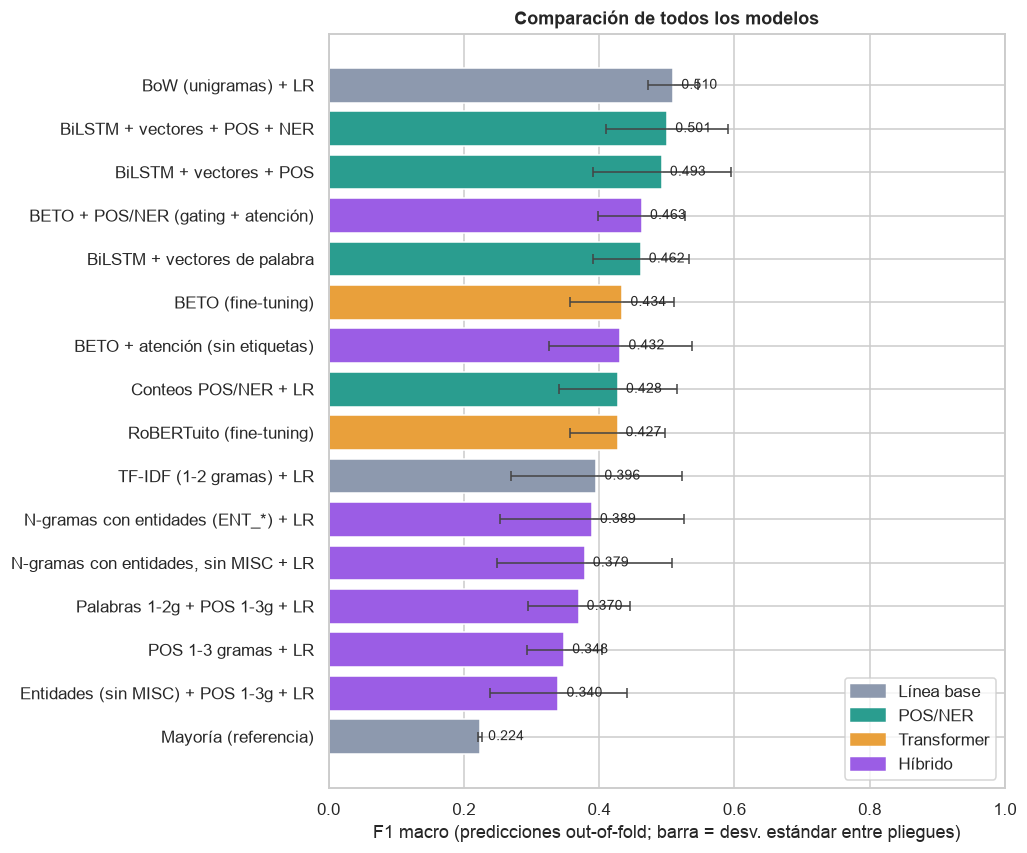

In [22]:
summ = pd.DataFrame({n: dict(**compute_metrics(y, r["pred"]), fam=r["family"], sd=r["fold_f1"].std()) for n, r in RESULTS.items()}).T
summ = summ.sort_values("f1")
fam_colors = {"Línea base": "#8D99AE", "POS/NER": "#2A9D8F", "Transformer": "#E9A03B", "Híbrido": "#9B5DE5"}
fig, ax = plt.subplots(figsize=(9.5, 0.42 * len(summ) + 1.2))
ax.barh(summ.index, summ.f1.astype(float), xerr=summ.sd.astype(float), color=[fam_colors[f] for f in summ.fam],
        error_kw=dict(ecolor="#444", capsize=3, lw=1))
for i, v in enumerate(summ.f1.astype(float)):
    ax.text(v + 0.012, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlabel("F1 macro (predicciones out-of-fold; barra = desv. estándar entre pliegues)")
ax.set_xlim(0, 1); ax.set_title("Comparación de todos los modelos")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in fam_colors.values()]
ax.legend(handles, fam_colors.keys(), loc="lower right", frameon=True)
plt.tight_layout(); plt.show()

### 5.1 Matrices de confusión (normalizadas por fila)

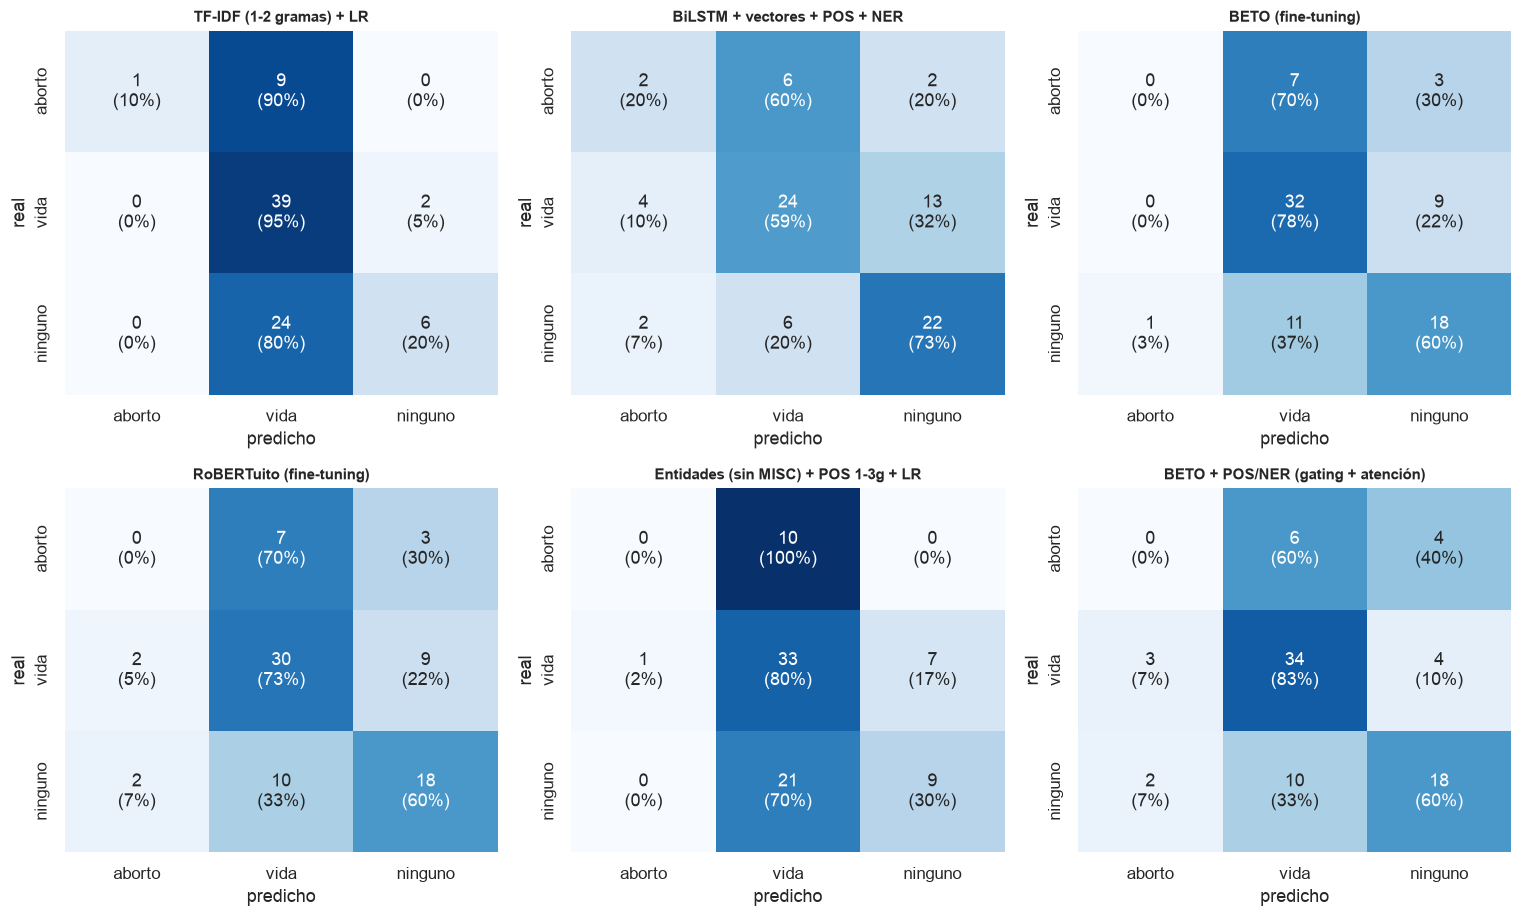

In [23]:
show = ["TF-IDF (1-2 gramas) + LR", "BiLSTM + vectores + POS + NER", "BETO (fine-tuning)", "RoBERTuito (fine-tuning)",
        "Entidades (sin MISC) + POS 1-3g + LR", "BETO + POS/NER (gating + atención)"]
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, n in zip(axes.ravel(), show):
    cm = confusion_matrix(y, RESULTS[n]["pred"], labels=[0, 1, 2])
    cmn = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cmn, annot=np.array([[f"{cm[i, j]}\n({cmn[i, j]:.0%})" for j in range(3)] for i in range(3)]), fmt="",
                cmap="Blues", vmin=0, vmax=1, cbar=False, xticklabels=LABELS, yticklabels=LABELS, ax=ax)
    ax.set_title(n, fontsize=10); ax.set_xlabel("predicho"); ax.set_ylabel("real")
plt.tight_layout(); plt.show()

### Comentarios · Comparación global
* **Mayor F1 macro:** BoW + LR (0.510), BiLSTM + vectores + POS + NER (0.501), BiLSTM + POS (0.493) y BETO + POS/NER (0.463). **Mayor exactitud:** BoW + LR y BETO + POS/NER (0.642).
* **Los intervalos de confianza se traslapan casi por completo** (p. ej. BoW [0.42, 0.61], BiLSTM + POS + NER [0.38, 0.62], BETO + POS/NER [0.39, 0.53]). Lo único firmemente establecido es que prácticamente todos los modelos superan la referencia de clase mayoritaria (F1 0.224, IC [0.19, 0.25]); **el orden entre ellos no es estadísticamente concluyente**.
* **Patrón común en las matrices de confusión:** todos los modelos colapsan hacia `vida` (la clase mayoritaria). `aborto` casi siempre se predice como `vida`; `ninguno` se reparte entre `vida` y `ninguno`. Los modelos TF-IDF envían a `vida` el 70-80 % de los `ninguno`; BiLSTM y transformers solo el 20-37 %.

### 5.2 Análisis de errores
¿Qué tipo de comentarios se clasifican mal? Se segmentan los 81 comentarios según rasgos lingüísticos observables
(longitud, presencia de entidades, vocabulario religioso, narración en primera persona) y se calcula la **tasa de error de cada modelo en cada segmento**.

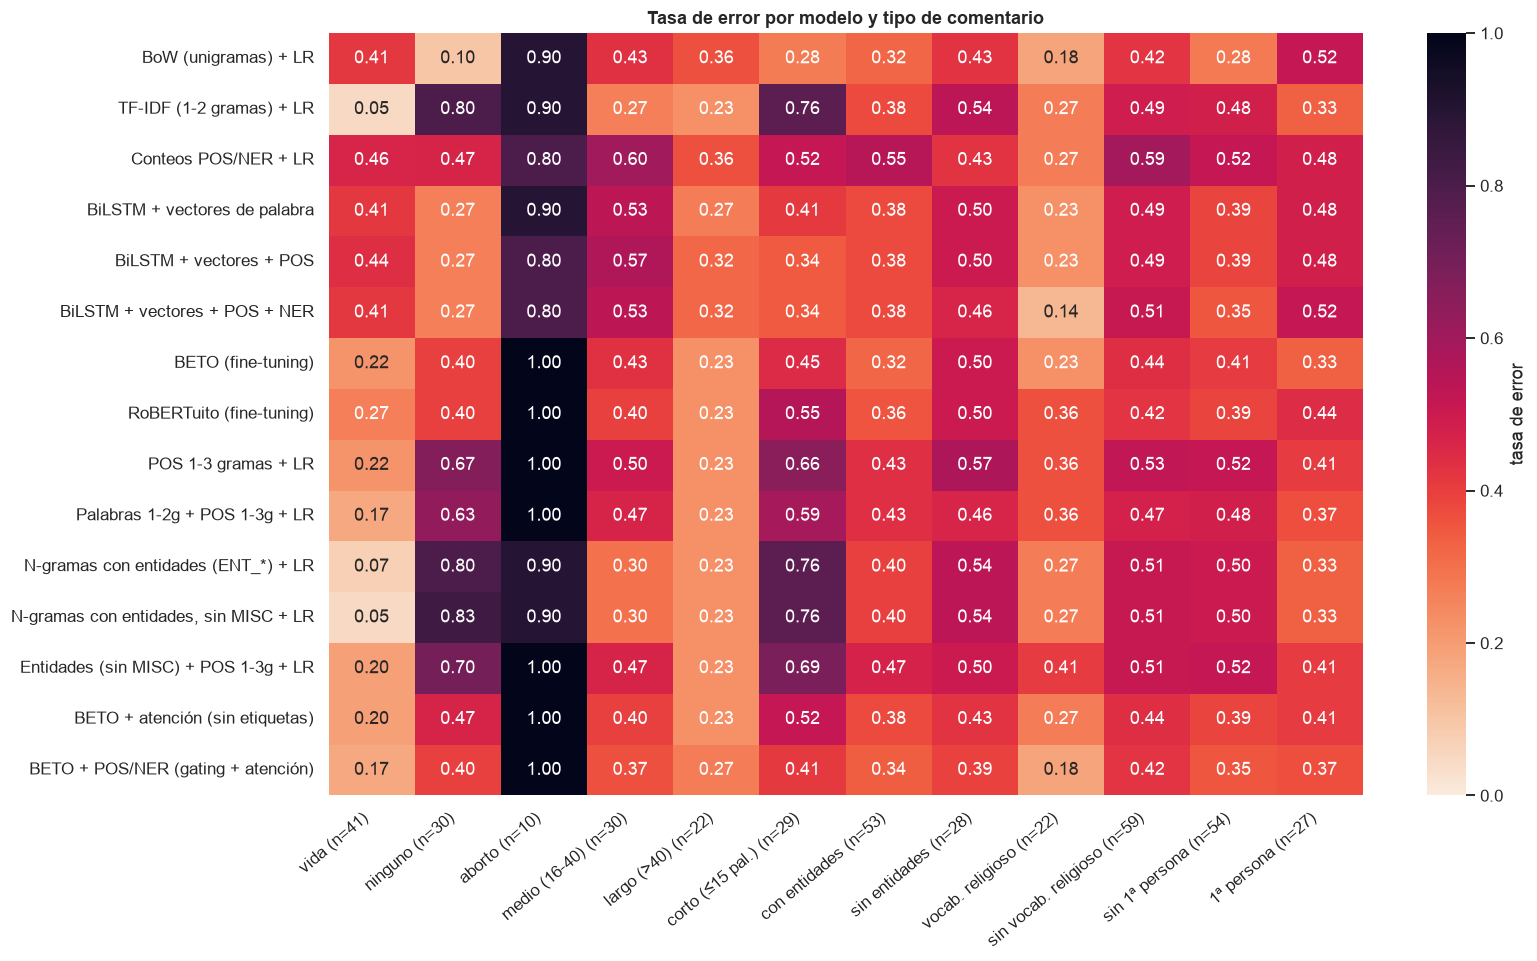

In [24]:
REL_RE = re.compile(r"\b(dios|señor|jesús|jesus|cristo|biblia|virgen|bendic\w*|oraci[oó]n|pecado|iglesia|am[eé]n|diosito|fe)\b", re.I)
FIRST_RE = re.compile(r"\b(yo|mi|mí|mis|me|soy|estoy|fui|tuve|hice|pasé|pase)\b", re.I)

seg = pd.DataFrame({
    "clase real": data.postura,
    "longitud": pd.cut(data.n_palabras, [0, 15, 40, 10**6], labels=["corto (≤15 pal.)", "medio (16-40)", "largo (>40)"]),
    "entidades": np.where(data.n_ents > 0, "con entidades", "sin entidades"),
    "religión": np.where(data.text_clean.str.contains(REL_RE), "vocab. religioso", "sin vocab. religioso"),
    "1ª persona": np.where(data.text_clean.str.contains(FIRST_RE), "1ª persona", "sin 1ª persona"),
})
MODELS = [n for n in RESULTS if not n.startswith("Mayoría")]
wrong = pd.DataFrame({n: RESULTS[n]["pred"] != y for n in MODELS})

cols = {}
for dim in seg.columns:
    for val in seg[dim].dropna().unique():
        m = (seg[dim] == val).values
        cols[f"{val} (n={m.sum()})"] = wrong[m].mean()
err_seg = pd.DataFrame(cols)
order = [c for c in err_seg.columns]
fig, ax = plt.subplots(figsize=(15, 0.42 * len(MODELS) + 2.6))
sns.heatmap(err_seg[order], annot=True, fmt=".2f", cmap="rocket_r", vmin=0, vmax=1, cbar_kws={"label": "tasa de error"}, ax=ax)
ax.set_title("Tasa de error por modelo y tipo de comentario"); plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

In [25]:
print("Tasa de error media (promedio de los modelos) por segmento:")
print(err_seg.mean().round(2).sort_values(ascending=False).to_string())

Tasa de error media (promedio de los modelos) por segmento:
aborto (n=10)                  0.93
corto (≤15 pal.) (n=29)        0.54
ninguno (n=30)                 0.50
sin entidades (n=28)           0.49
sin vocab. religioso (n=59)    0.48
medio (16-40) (n=30)           0.44
sin 1ª persona (n=54)          0.43
1ª persona (n=27)              0.41
con entidades (n=53)           0.39
vocab. religioso (n=22)        0.27
largo (>40) (n=22)             0.26
vida (n=41)                    0.25


### 5.3 Los comentarios más difíciles

In [26]:
n_wrong = wrong.sum(1)
hard = data.assign(n_modelos_fallan=n_wrong, real=data.postura,
                   pred_mas_comun=[LABELS[np.bincount([RESULTS[n]["pred"][i] for n in MODELS], minlength=3).argmax()] for i in range(len(data))])
print(f"Comentarios mal clasificados por TODOS los modelos ({len(MODELS)}): {(n_wrong == len(MODELS)).sum()}")
print(f"Comentarios que ningún modelo falla: {(n_wrong == 0).sum()}")
pd.set_option("display.max_colwidth", 140)
hard.sort_values("n_modelos_fallan", ascending=False).head(12)[["real", "pred_mas_comun", "n_modelos_fallan", "text_clean"]]\
    .assign(text_clean=lambda d: d.text_clean.str.slice(0, 135)).reset_index(drop=True)

Comentarios mal clasificados por TODOS los modelos (15): 7
Comentarios que ningún modelo falla: 14


,real,pred_mas_comun,n_modelos_fallan,text_clean
0,aborto,ninguno,15,ABORTO LEGAL Al feto lo venden por Amazon
1,vida,ninguno,15,¿Hasta dónde son capaces de mentir con tal de asesinar a los más inocentes?
2,aborto,vida,15,"A favor del aborto. Y ¿Por qué a favor? Antes que nada, quiero aclarar: No soy feminista ni nada por el estilo. Ahora sí. Yo estoy a fa"
3,aborto,vida,15,"Yo estoy en contra, pero en lo unico que estoy de acuerdo, es que se realize en casos de violacion, en todo lo demas, ni hablar. Uno de"
4,aborto,vida,15,JAJAJAJAJAJAJAJA fui a un año a una escuela cristiana y una maestra nos dijo que los abortos era un asesinato y que sacaban al bebé de
5,aborto,vida,15,Números 5:11-34 no dice nada del aborto. Miren el texto en su contexto antes de emitir información. Los que vean esto busquen y corrobo
6,ninguno,vida,15,"El que juzga es porque no conocio jamas A Dios!!! El es el Unico que pide cuentas...."" El que este libre de pecado que tire la primera"
7,ninguno,vida,14,"Estas personas que pecan luego se refugian en el nombre dios, unas blasfemias nunca van a ir al cielo"
8,aborto,vida,14,ya somos un chingo en este planeta!!!
9,aborto,vida,14,"Yo estoy a favor del aborto siempre y cuando sea dentro de los primeros 3 meses de gestación, cuando apenas es un cigoto. Abortar fuera"


**¿Cambian los POS de los comentarios mal clasificados?** Distribución de POS en aciertos vs. errores del mejor modelo.

Mejor modelo por F1 macro: BoW (unigramas) + LR


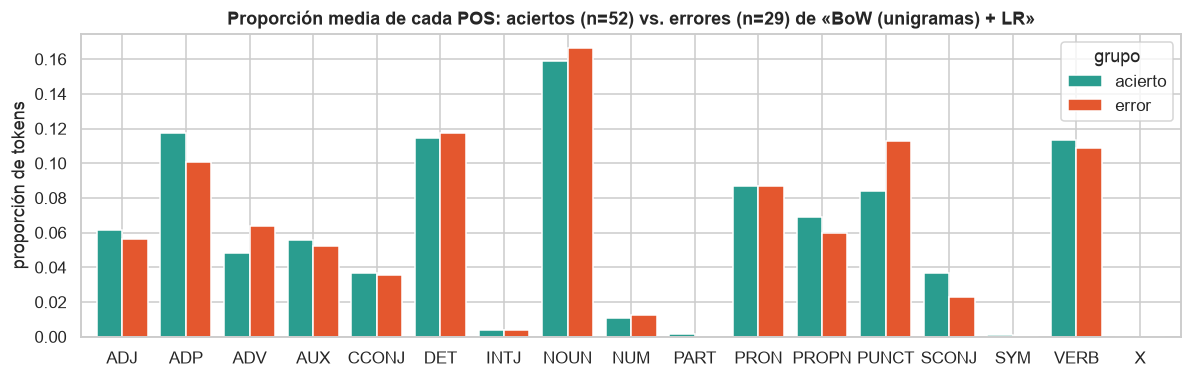

In [27]:
best = max(MODELS, key=lambda n: compute_metrics(y, RESULTS[n]["pred"])["f1"])
print("Mejor modelo por F1 macro:", best)
ok = RESULTS[best]["pred"] == y
rows = []
for a, o in zip(A, ok):
    n = len(a["pos"]); cnt = np.bincount(a["pos_id"], minlength=len(UPOS)) / n
    rows.append(dict(grupo="acierto" if o else "error", **dict(zip(UPOS, cnt))))
pg = pd.DataFrame(rows).groupby("grupo")[UPOS].mean().T[["acierto", "error"]]
ax = pg.plot.bar(figsize=(11, 3.6), color=["#2A9D8F", "#E4572E"], width=0.8)
ax.set_title(f"Proporción media de cada POS: aciertos (n={ok.sum()}) vs. errores (n={(~ok).sum()}) de «{best}»")
ax.set_ylabel("proporción de tokens"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

### Comentarios · Errores
* **Por clase:** `aborto` es la clase más difícil (tasa de error media **93 %**, 10 comentarios), seguida de `ninguno` (50 %); `vida` solo falla 25 %. Los comentarios pro-aborto **comparten vocabulario con los pro-vida** (citan sus argumentos, usan *aborto*, *feto*, *vida*) y son pocos.
* **Por longitud:** los comentarios cortos (≤ 15 palabras) fallan 54 % frente a 26 % de los largos: sin contexto, las posturas implícitas no se pueden inferir.
* **Por vocabulario:** los comentarios con vocabulario religioso fallan menos (27 % vs. 48 %), pero ese vocabulario aparece tanto en `vida` como en `ninguno` (*Dios* es la entidad más frecuente de ambas), lo que explica la confusión `vida`↔`ninguno`. Con entidades los modelos fallan menos (39 % vs. 49 %).
* **POS:** los errores del mejor modelo tienen más signos de puntuación y adverbios y menos conjunciones subordinantes (menos oraciones argumentadas, más exclamaciones y frases sueltas).
* **Casos más difíciles** (7 comentarios fallados por los 15 modelos; 14 que ningún modelo falla): sarcasmo o postura implícita (*«¿Hasta dónde son capaces de mentir con tal de asesinar a los más inocentes?»* —una persona lo lee como pro-vida pero no contiene ninguna palabra de postura—; *«ABORTO LEGAL Al feto lo venden por Amazon»*), posturas matizadas (*«Yo estoy en contra, pero…» en caso de violación*),
  humor/ironía (*«JAJAJA fui a una escuela cristiana…»*) y comentarios que requieren conocimiento externo (*«ya somos un chingo en este planeta»*). Algunos de estos casos son ambiguos incluso para una persona, de modo que parte del error refleja ruido en la etiqueta y no solo debilidad del modelo.

## Reporte resumen

**Problema.** Clasificar la postura de comentarios de YouTube en español sobre el aborto en tres clases: `vida` (pro-vida), `aborto` (pro-aborto) y `ninguno` (sin postura). Se compararon 15 configuraciones en cuatro familias: línea base (BoW/TF-IDF), características POS/NER (conteos y BiLSTM), *fine-tuning* de transformers (BETO, RoBERTuito) y modelos híbridos (n-gramas de POS, n-gramas con entidades, BETO + POS/NER con compuerta y atención).

**Protocolo.** El corpus contiene 200 comentarios únicos, de los cuales 81 están etiquetados (41 `vida`, 30 `ninguno`, 10 `aborto`); solo estos se usan para entrenar y evaluar. Todos están en español (verificado con `langdetect`), por lo que se usaron modelos preentrenados en español. Evaluación con validación cruzada estratificada de 5 pliegues, mismos pliegues para todos los modelos, predicciones *out-of-fold*, F1 macro como métrica principal e IC 95 % por *bootstrap*.

| Modelo | Accuracy | F1 macro | F1 `aborto` |
|---|---|---|---|
| Mayoría (referencia) | 0.506 | 0.224 | 0.00 |
| BoW + LR | **0.642** | **0.510** | 0.11 |
| TF-IDF 1-2g + LR | 0.568 | 0.396 | 0.18 |
| BiLSTM + vectores + POS + NER | 0.593 | 0.501 | 0.22 |
| BETO (fine-tuning) | 0.617 | 0.434 | 0.00 |
| RoBERTuito (fine-tuning) | 0.593 | 0.427 | 0.00 |
| POS 1-3 gramas + LR | 0.519 | 0.348 | 0.00 |
| N-gramas con entidades + LR | 0.556 | 0.389 | 0.18 |
| BETO + POS/NER (gating + atención) | **0.642** | 0.463 | 0.00 |

**Hallazgos principales.**
1. **Ningún enfoque domina de forma demostrable.** El mejor F1 macro (BoW, 0.51) y el mejor modelo con transformers (BETO + POS/NER, 0.46) tienen intervalos de confianza traslapados; con 81 comentarios, diferencias de 3-5 puntos son ruido. Todos superan claramente a la referencia (0.22).
2. **Las etiquetas lingüísticas ayudan de forma modesta y consistente en dirección:** BiLSTM 0.462 → 0.501 al añadir POS y NER; BETO 0.432 → 0.463 al añadir POS/NER (frente al control con la misma atención). No son mejoras concluyentes, pero se repiten en dos arquitecturas distintas.
3. **Los transformers no aprovechan su ventaja con tan pocos datos:** logran buena exactitud y el mejor F1 en `vida` (0.75), pero **nunca predicen `aborto`**. El preentrenamiento en redes sociales (RoBERTuito) no superó a BETO.
4. **Sustituir entidades y usar n-gramas de POS no mejora** a los n-gramas de palabras: el NER de spaCy es ruidoso en texto informal y los nombres propios (*Dios*, *Jesús*) llevan señal ideológica; la sintaxis sola separa comentarios cortos de largos, no posturas.

**Fortalezas y debilidades.** *BoW/TF-IDF*: rápidos, interpretables y competitivos con poco dato, pero aprenden estilo y longitud, y TF-IDF con bigramas se sobreajusta a la clase mayoritaria. *POS/NER + BiLSTM*: pequeña mejora y bajo costo, pero dependen de un NER poco fiable en este dominio. *Transformers*: mejor comprensión de `vida`/`ninguno`, pero ignoran la clase minoritaria y necesitan más datos. *Híbrido con compuerta y atención*: el más completo y el único con atención inspeccionable, a mayor costo y sin ganancia demostrada.

**Patrones de error.** (i) `aborto` es la clase más difícil (error medio 93 %): comparte vocabulario con `vida` y tiene solo 10 ejemplos; (ii) los comentarios cortos fallan el doble que los largos (54 % vs. 26 %); (iii) el vocabulario religioso aparece en `vida` y en `ninguno` y produce confusión entre ambas; (iv) los casos más difíciles requieren sarcasmo, postura implícita o conocimiento del mundo, y algunos son ambiguos incluso para una persona.

**Limitaciones y siguientes pasos.** El principal límite es el tamaño y el desbalance del corpus etiquetado (81 comentarios, 10 de `aborto`): los resultados son indicativos, no concluyentes. Los pasos con mayor retorno esperado son (1) etiquetar más comentarios, sobre todo de la clase `aborto`, (2) usar un NER y un POS adaptados a texto informal y (3) repetir la comparación con más datos, donde los transformers y el modelo híbrido deberían separarse de la línea base.